# ♟️ Lichess Bulmaca Zorluğu — Keşifsel Veri Analizi (EDA)

**Amaç:** Bir satranç bulmacasının **tahta pozisyonundan (FEN)** ve **çözüm hamlelerinden (Moves)**, o bulmacanın insanlar için ne kadar zor olduğunu gösteren **Glicko-2 puanını (`Rating`)** tahmin etmek. Problem bir **regresyondur**; hedef sürekli bir sayıdır (ör. 1760).

Bu notebook modele geçmeden önce veriyi tanımak için hazırlandı. Her bölümde önce **neden baktığımızı**, sonra grafiği ve grafiğin altında hesaplanmış **📌 bulguyu** göreceksin.

| | |
|---|---|
| **Veri kaynağı** | [Lichess Open Database – Puzzles](https://database.lichess.org/#puzzles) |
| **Sürüm** | 5 Ekim 2026 · 6.157.341 bulmaca · 11 sütun |
| **Lisans** | CC0 (kamu malı) |
| **Bu notebook'taki örneklem** | `RatingDeviation ≤ 90` filtresinden sonra rastgele **500.000** bulmaca (`random_state=42`) |
| **İlgili yarışmalar** | IEEE BigData Cup 2024 · FedCSIS 2025 *Predicting Chess Puzzle Difficulty* |

### İçindekiler
1. Veriye ilk bakış
2. Hedef değişken: `Rating` (dağılım, belirsizlik, 1500 yığılması, zorluk bantları)
3. Bulmacanın yapısı (çözüm uzunluğu, temalar, oyun evresi)
4. Tahtadan çıkarılan öznitelikler (`python-chess`)
5. Sızıntı (leakage) kontrolü
6. Özet ve modelleme kararları

<details>
<summary><b>Veri hazırlama adımı (bir kez çalıştırıldı, burada sadece kayıt için duruyor)</b></summary>

```python
!pip install -q python-chess zstandard
!wget -q https://database.lichess.org/lichess_db_puzzle.csv.zst

import pandas as pd
df = pd.read_csv("lichess_db_puzzle.csv.zst")
df = df[df["RatingDeviation"] <= 90]
df = df.sample(n=500_000, random_state=42).reset_index(drop=True)
df.to_parquet("/kaggle/working/puzzles_500k.parquet")
```
Çıktı dosyası `puzzles_500k.parquet` olarak bir Kaggle veri setine yüklendi ve bu notebook'a **Input** olarak eklendi.
</details>

## 0. Kurulum
Kütüphaneler, grafik stili ve küçük yardımcı fonksiyonlar. Tüm grafiklerde tek bir vurgu rengi (mavi) kullanılıyor; gri ikincil bilgileri, turuncu ise referans çizgilerini gösteriyor.

In [1]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# --- Renkler ---
MAVI, TURUNCU = "#2a78d6", "#eb6834"
GRI, ACIK_GRI = "#a3a19a", "#e4e2dc"
YAZI, YAZI2 = "#0b0b0b", "#52514e"
ZEMIN = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": ZEMIN, "axes.facecolor": ZEMIN, "savefig.facecolor": ZEMIN,
    "figure.dpi": 110, "font.size": 11, "font.family": "DejaVu Sans",
    "axes.edgecolor": "#cfcdc6", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": YAZI, "axes.labelcolor": YAZI2, "axes.labelsize": 11,
    "xtick.color": YAZI2, "ytick.color": YAZI2, "legend.frameon": False,
})
pd.set_option("display.max_columns", 30)

def tr(x, ondalik=0):
    # Sayıyı Türkçe biçimde yazar: 1234567.8 -> 1.234.567,8
    s = f"{x:,.{ondalik}f}"
    return s.replace(",", "§").replace(".", ",").replace("§", ".")

def yuzde(x, ondalik=1):
    return "%" + tr(100 * x, ondalik)

def baslik(ax, ana, alt=None):
    ax.set_title(ana, pad=26 if alt else 10)
    if alt:
        ax.text(0, 1.015, alt, transform=ax.transAxes, color=YAZI2, fontsize=10, va="bottom")

def bulgu(metin):
    display(Markdown(f"> 📌 **Bulgu:** {metin}"))

def binli_medyan(ax, x, y, kenarlar, renk=MAVI, xetiket="", tamsayi=True):
    # x'i aralıklara böler; her aralıkta y'nin medyanını (çizgi) ve Q1–Q3 bandını (gölge) çizer.
    gruplar = pd.cut(x, kenarlar, include_lowest=True, duplicates="drop")
    g = pd.DataFrame({"g": gruplar, "y": y}).groupby("g", observed=True)["y"]
    ozet = pd.DataFrame({"med": g.median(), "q1": g.quantile(.25), "q3": g.quantile(.75), "n": g.size()})
    ozet = ozet[ozet["n"] >= 50]
    xs = np.arange(len(ozet))
    ax.fill_between(xs, ozet["q1"], ozet["q3"], color=renk, alpha=.15, lw=0, label="Çeyrekler arası (Q1–Q3)")
    ax.plot(xs, ozet["med"], color=renk, lw=2, marker="o", ms=6, label="Medyan")
    etiketler = []
    for a in ozet.index:
        if tamsayi:
            lo, hi = int(round(a.left)) + 1, int(round(a.right))
            etiketler.append(str(hi) if lo >= hi else f"{lo}–{hi}")
        else:
            etiketler.append(f"{round(a.left)}–{round(a.right)}")
    ax.set_xticks(xs)
    ax.set_xticklabels(etiketler, rotation=45 if len(xs) > 7 else 0, ha="right" if len(xs) > 7 else "center")
    ax.set_xlabel(xetiket)
    ax.set_ylabel("Rating")
    ax.legend(loc="upper left", fontsize=9)
    return ozet

def kantil_kenar(x, n=10):
    # Tamsayı öznitelikler için yaklaşık eşit dolulukta aralık kenarları
    k = np.unique(np.quantile(x, np.linspace(0, 1, n + 1)).round())
    k[0] = k[0] - 1
    return k

def kutu(ax, veri, etiketler, renk=MAVI, yatay=False):
    # Aykırı değerleri gizlenmiş kutu grafiği + her kutunun üstünde medyan değeri.
    bp = ax.boxplot(veri, vert=not yatay, showfliers=False, patch_artist=True, widths=.55,
                    medianprops=dict(color=YAZI, lw=2), whiskerprops=dict(color=GRI),
                    capprops=dict(color=GRI), boxprops=dict(edgecolor=renk))
    konum = range(1, len(veri) + 1)
    (ax.set_yticks if yatay else ax.set_xticks)(list(konum))
    (ax.set_yticklabels if yatay else ax.set_xticklabels)(etiketler)
    for kutu_ in bp["boxes"]:
        kutu_.set_facecolor(renk); kutu_.set_alpha(.30)
    for i, v in enumerate(veri, start=1):
        m = np.median(v)
        if yatay:
            ax.text(m, i + .33, tr(m), ha="center", va="bottom", fontsize=9, color=YAZI)
        else:
            ax.text(i + .30, m, tr(m), ha="left", va="center", fontsize=9, color=YAZI)
    return bp

print("Kurulum tamam ✔")

Kurulum tamam ✔


In [2]:
# Veri dosyalarını Kaggle Input klasöründe bul
ARAMA = ["/kaggle/input", os.environ.get("EDA_VERI_KLASORU", "/kaggle/input")]
def bul(desen):
    for kok in ARAMA:
        sonuc = sorted(glob.glob(os.path.join(kok, "**", desen), recursive=True))
        if sonuc:
            return sonuc[0]
    return None

PARQUET = bul("puzzles_500k.parquet")
TUM_CSV = bul("lichess_db_puzzle.csv*")
print("Örneklem dosyası :", PARQUET)
print("Tam veri dosyası :", TUM_CSV)

df = pd.read_parquet(PARQUET)
print(f"\nÖrneklem: {tr(len(df))} satır × {df.shape[1]} sütun · bellek ≈ {tr(df.memory_usage(deep=True).sum() / 1e6)} MB")

Örneklem dosyası : /kaggle/input/datasets/hamzabilici/lichess-db/puzzles_500k.parquet
Tam veri dosyası : /kaggle/input/datasets/hamzabilici/lichess-db/lichess_db_puzzle.csv.zst

Örneklem: 500.000 satır × 11 sütun · bellek ≈ 239 MB


## 1. Veriye ilk bakış
Her satır bir bulmaca. `FEN` ve `Moves` metin gibi görünse de birer **satranç gösterimidir** (NLP değil); bölüm 4'te `python-chess` ile sayısal özniteliklere çevireceğiz.

In [3]:
display(df.head(5))

,PuzzleId,FEN,Moves,Rating,RatingDeviation,Popularity,NbPlays,Themes,GameUrl,OpeningTags,DailyDate
0,bkpg3,r3r1k1/2q2pp1/2p4p/1p6/pPpP1nP1/P1P2N1P/7Q/R3R...,f4e2 e1e2 c7h2 e2h2,1425,74,94,3040,advantage middlegame short,https://lichess.org/IIRF4olT/black#50,None,NaN
1,4AG2R,5rk1/pp3p1p/2p2p1q/4PQ2/4BR2/5KP1/3r3P/8 b - -...,h6h2 f4g4 g8h8 f5f6,1646,75,95,7562,endgame mate mateIn2 short,https://lichess.org/oCqTk0o6/black#50,None,NaN
2,VTR9q,r3k2r/ppp2pp1/2p5/2P5/4P1b1/2P5/PP3P1p/RNB1R2K...,c1f4 g4f3,695,79,100,210,mate mateIn1 middlegame oneMove,https://lichess.org/zMIQncOt#31,Petrovs_Defense Petrovs_Defense_Stafford_Gambit,NaN
3,ovKJT,4r1k1/6pQ/4pp2/p1BpP3/3P4/1r6/3q1PK1/7R b - - ...,g8f7 h7h5 g7g6 h5h7,1124,75,96,704,endgame mate mateIn2 short,https://lichess.org/mGsL9cUG/black#82,None,NaN
4,bQ9iR,1q5k/6p1/3bN2p/8/2r5/8/4RPP1/3Q3K w - - 0 40,d1a1 c4h4 h1g1 d6h2 g1f1 h2e5,1775,83,87,58,crushing endgame long,https://lichess.org/UjT16odR#79,None,NaN


In [4]:
aciklama = {
    "PuzzleId":        ("Bulmaca kimliği", "Kimlik"),
    "FEN":             ("Rakip hamlesinden ÖNCEKİ tahta pozisyonu", "Girdi"),
    "Moves":           ("Çözüm hamleleri (UCI); ilk hamle rakibin", "Girdi"),
    "Rating":          ("Glicko-2 zorluk puanı", "🎯 HEDEF"),
    "RatingDeviation": ("Puanın belirsizliği (düşük = güvenilir)", "Sadece filtre"),
    "Popularity":      ("Oy skoru (−100 … 100)", "⚠️ Sızıntı"),
    "NbPlays":         ("Kaç kez oynandığı", "⚠️ Sızıntı"),
    "Themes":          ("Taktik temalar (fork, mate, …)", "Dikkatli kullan"),
    "GameUrl":         ("Bulmacanın alındığı oyun", "Kullanılmaz"),
    "OpeningTags":     ("Açılış adı (sadece 20. hamleden önce)", "Opsiyonel"),
    "DailyDate":       ("Günün bulmacası seçildiyse tarihi", "Kullanılmaz"),
}
sozluk = pd.DataFrame({
    "Açıklama":       [aciklama.get(c, ("", ""))[0] for c in df.columns],
    "Modeldeki rolü": [aciklama.get(c, ("", ""))[1] for c in df.columns],
    "Veri tipi":      df.dtypes.astype(str).values,
    "Eksik (%)":      (df.isna().mean() * 100).round(1).values,
    "Benzersiz değer": [tr(df[c].nunique()) for c in df.columns],
}, index=df.columns)
sozluk.index.name = "Sütun"
display(sozluk)

,Açıklama,Modeldeki rolü,Veri tipi,Eksik (%),Benzersiz değer
Sütun,,,,,
PuzzleId,Bulmaca kimliği,Kimlik,object,0.0,500.000
FEN,Rakip hamlesinden ÖNCEKİ tahta pozisyonu,Girdi,object,0.0,499.970
Moves,Çözüm hamleleri (UCI); ilk hamle rakibin,Girdi,object,0.0,464.282
Rating,Glicko-2 zorluk puanı,🎯 HEDEF,int64,0.0,2.463
RatingDeviation,Puanın belirsizliği (düşük = güvenilir),Sadece filtre,int64,0.0,28
Popularity,Oy skoru (−100 … 100),⚠️ Sızıntı,int64,0.0,101
NbPlays,Kaç kez oynandığı,⚠️ Sızıntı,int64,0.0,24.526
Themes,"Taktik temalar (fork, mate, …)",Dikkatli kullan,object,0.0,20.504
GameUrl,Bulmacanın alındığı oyun,Kullanılmaz,object,0.0,500.000


In [5]:
sayisal = ["Rating", "RatingDeviation", "Popularity", "NbPlays"]
ozet = df[sayisal].describe(percentiles=[.05, .25, .5, .75, .95]).T
ozet.columns = ["Adet", "Ortalama", "Std. sapma", "Min", "%5", "%25", "Medyan", "%75", "%95", "Maks"]
display(ozet.style.format(lambda v: tr(v)))

,Adet,Ortalama,Std. sapma,Min,%5,%25,Medyan,%75,%95,Maks
Sütun,,,,,,,,,,
Rating,500.000,1.501,476,399,790,1.130,1.469,1.854,2.316,2.969
RatingDeviation,500.000,79,4,57,74,76,77,81,88,90
Popularity,500.000,88,10,0,69,85,91,94,100,100
NbPlays,500.000,2.140,5.150,19,56,167,511,1.771,10.585,255.184


### Türetilen yardımcı sütunlar
Grafiklerde kullanmak için `Moves` ve `Themes` sütunlarından birkaç basit sütun türetiyoruz:
- **`cozum_uzunlugu`**: oyuncunun yapması gereken hamle sayısı (`Moves` içindeki ilk hamle rakibin olduğu için toplam hamle / 2)
- **`cozen_taraf`**: bulmacayı çözen renk (FEN'de sıra kimdeyse, çözen diğer taraftır)
- **`faz`**: temalardaki *opening / middlegame / endgame* etiketi
- **`bant`**: zorluk bandı (<1000, 1000–1399, 1400–1699, ≥1700)

In [6]:
hamleler = df["Moves"].str.split()
df["cozum_uzunlugu"] = hamleler.str.len() // 2
df["cozen_taraf"] = np.where(df["FEN"].str.split().str[1] == "w", "Siyah", "Beyaz")
df["tema_listesi"] = df["Themes"].fillna("").str.split()

def faz_bul(temalar):
    for t, ad in [("opening", "Açılış"), ("middlegame", "Orta oyun"), ("endgame", "Oyun sonu")]:
        if t in temalar:
            return ad
    return "Belirsiz"
df["faz"] = df["tema_listesi"].apply(faz_bul)

BANT_KENAR = [0, 1000, 1400, 1700, 4000]
BANT_AD = ["<1000", "1000–1399", "1400–1699", "≥1700"]
df["bant"] = pd.cut(df["Rating"], BANT_KENAR, labels=BANT_AD, right=False)

display(df[["PuzzleId", "Rating", "cozum_uzunlugu", "cozen_taraf", "faz", "bant"]].head())

Sütun,PuzzleId,Rating,cozum_uzunlugu,cozen_taraf,faz,bant
0,bkpg3,1425,2,Beyaz,Orta oyun,1400–1699
1,4AG2R,1646,2,Beyaz,Oyun sonu,1400–1699
2,VTR9q,695,1,Siyah,Orta oyun,<1000
3,ovKJT,1124,2,Beyaz,Oyun sonu,1000–1399
4,bQ9iR,1775,3,Siyah,Oyun sonu,≥1700


## 2. Hedef değişken: `Rating`
Lichess'te her yeni bulmaca **1500** puanla başlar; her çözme denemesi oyuncu ile bulmaca arasında Glicko-2 dereceli bir maç gibi sayılır. Yeterince oynanmamış bulmacalar 1500 civarında takılı kalır. Yarışma makalelerinde bu yığılma **etiket gürültüsü** olarak tanımlanıyor.

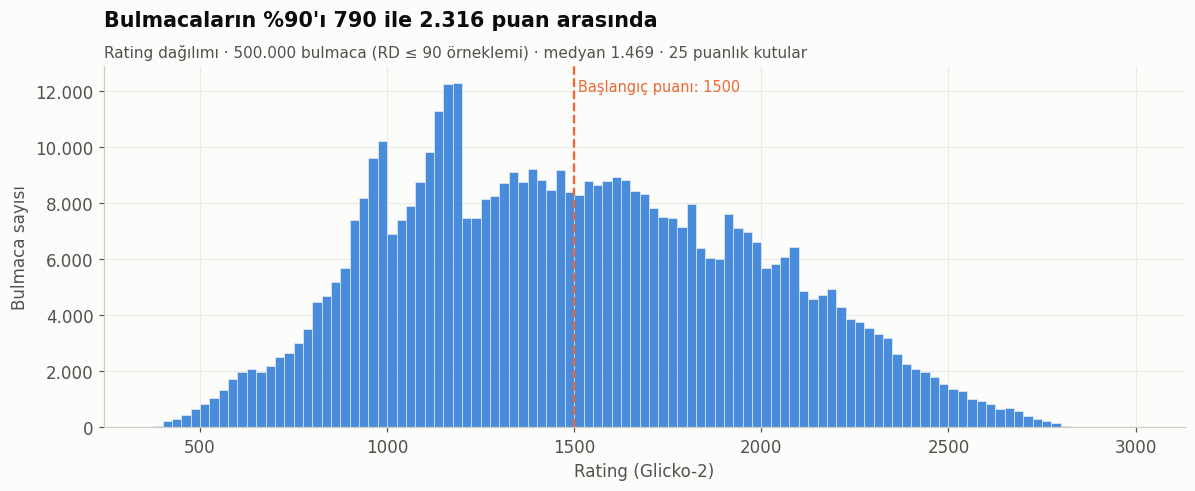

> 📌 **Bulgu:** Ortalama 1.501, medyan 1.469, standart sapma 476. Çarpıklık 0,23 (sağa çarpık). Uçlarda (çok kolay / çok zor) az bulmaca var; literatürde modellerin en çok bu uçlarda hata yaptığı raporlanıyor.

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.6))
kenarlar = np.arange(375, df["Rating"].max() + 50, 25)
ax.hist(df["Rating"], bins=kenarlar, color=MAVI, alpha=.85, edgecolor=ZEMIN, linewidth=.4)
med = df["Rating"].median()
ax.axvline(1500, color=TURUNCU, ls="--", lw=1.5)
ax.text(1510, ax.get_ylim()[1] * .93, "Başlangıç puanı: 1500", color=TURUNCU, fontsize=9.5)
q5, q95 = df["Rating"].quantile([.05, .95])
baslik(ax, f"Bulmacaların %90'ı {tr(q5)} ile {tr(q95)} puan arasında",
       f"Rating dağılımı · {tr(len(df))} bulmaca (RD ≤ 90 örneklemi) · medyan {tr(med)} · 25 puanlık kutular")
ax.set_xlabel("Rating (Glicko-2)"); ax.set_ylabel("Bulmaca sayısı")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: tr(v)))
plt.tight_layout(); plt.show()

carp = df["Rating"].skew()
bulgu(f"Ortalama {tr(df['Rating'].mean())}, medyan {tr(med)}, standart sapma {tr(df['Rating'].std())}. "
      f"Çarpıklık {tr(carp, 2)} ({'sağa' if carp > 0 else 'sola'} çarpık). Uçlarda (çok kolay / çok zor) az bulmaca var; "
      "literatürde modellerin en çok bu uçlarda hata yaptığı raporlanıyor.")

### 2.1 Puan belirsizliği (`RatingDeviation`) ve 1500 yığılması
Bu bölümde 500 binlik örneklem yerine **6,1 milyonluk tam veriyi** kullanıyoruz; çünkü örneklemi zaten `RatingDeviation ≤ 90` ile filtreledik ve filtrenin etkisini ancak tam veride görebiliriz. Sadece 3 sütun okunduğu için bu adım yaklaşık bir dakika sürer.

In [8]:
TUM_OK = False
try:
    t0 = time.time()
    tum = pd.read_csv(TUM_CSV, usecols=["Rating", "RatingDeviation", "NbPlays"])
    TUM_OK = True
    print(f"Tam veri okundu: {tr(len(tum))} bulmaca · {tr(time.time() - t0)} sn")
except Exception as e:
    print("Tam veri okunamadı, bu bölüm örneklemle sınırlı kalacak:", e)

Tam veri okundu: 6.157.341 bulmaca · 13 sn


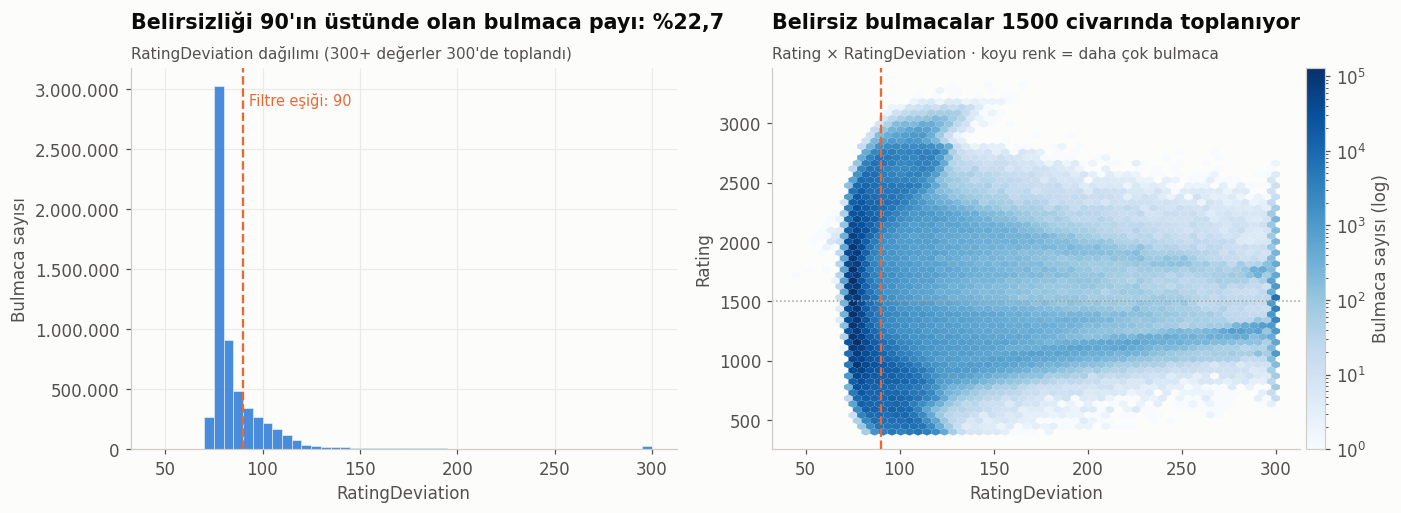

> 📌 **Bulgu:** RD > 90 olan bulmacaların puan standart sapması 730, RD ≤ 90 olanlarınki 476. İki grubun yayılımı beklenenden farklı; filtre kararını bu grafiğe bakarak yeniden düşün.

In [9]:
if TUM_OK:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.15]})

    rd = tum["RatingDeviation"].clip(upper=300)
    ax1.hist(rd, bins=np.arange(rd.min() // 5 * 5, 305, 5), color=MAVI, alpha=.85, edgecolor=ZEMIN, linewidth=.4)
    ax1.axvline(90, color=TURUNCU, ls="--", lw=1.5)
    ax1.text(93, ax1.get_ylim()[1] * .9, "Filtre eşiği: 90", color=TURUNCU, fontsize=9.5)
    ust = (tum["RatingDeviation"] > 90).mean()
    baslik(ax1, f"Belirsizliği 90'ın üstünde olan bulmaca payı: {yuzde(ust)}",
           "RatingDeviation dağılımı (300+ değerler 300'de toplandı)")
    ax1.set_xlabel("RatingDeviation"); ax1.set_ylabel("Bulmaca sayısı")
    ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: tr(v)))

    hb = ax2.hexbin(tum["RatingDeviation"].clip(upper=300), tum["Rating"], gridsize=55, bins="log",
                    cmap="Blues", mincnt=1, linewidths=0)
    ax2.axvline(90, color=TURUNCU, ls="--", lw=1.5)
    ax2.axhline(1500, color=GRI, ls=":", lw=1)
    cb = fig.colorbar(hb, ax=ax2, pad=.01); cb.set_label("Bulmaca sayısı (log)", color=YAZI2)
    baslik(ax2, "Belirsiz bulmacalar 1500 civarında toplanıyor", "Rating × RatingDeviation · koyu renk = daha çok bulmaca")
    ax2.set_xlabel("RatingDeviation"); ax2.set_ylabel("Rating"); ax2.grid(False)
    plt.tight_layout(); plt.show()

    yuksek = tum.loc[tum["RatingDeviation"] > 90, "Rating"]
    dusuk = tum.loc[tum["RatingDeviation"] <= 90, "Rating"]
    yorum = ("Belirsiz bulmacalar 1500 çevresinde daha dar bir bantta sıkışmış; bunları eğitimden çıkarmak etiket gürültüsünü azaltır."
             if yuksek.std() < dusuk.std() else "İki grubun yayılımı beklenenden farklı; filtre kararını bu grafiğe bakarak yeniden düşün.")
    bulgu(f"RD > 90 olan bulmacaların puan standart sapması {tr(yuksek.std())}, RD ≤ 90 olanlarınki {tr(dusuk.std())}. " + yorum)
else:
    print("Tam veri olmadan bu grafik çizilemiyor.")

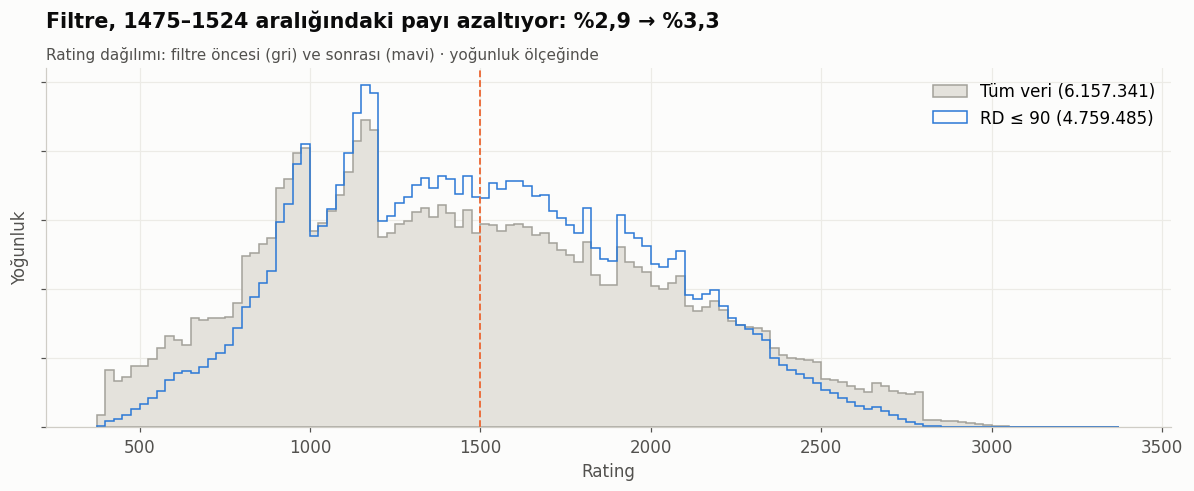

> 📌 **Bulgu:** 1475–1524 aralığına düşen bulmaca payı filtre öncesi %2,9, sonrası %3,3. Filtre 1500 tepesini küçültmedi; eşiği gözden geçir.

In [10]:
if TUM_OK:
    fig, ax = plt.subplots(figsize=(11, 4.6))
    kenarlar = np.arange(375, 3400, 25)
    ax.hist(tum["Rating"], bins=kenarlar, density=True, histtype="stepfilled", color=ACIK_GRI,
            edgecolor=GRI, label=f"Tüm veri ({tr(len(tum))})")
    ax.hist(tum.loc[tum["RatingDeviation"] <= 90, "Rating"], bins=kenarlar, density=True, histtype="step",
            color=MAVI, lw=2, label=f"RD ≤ 90 ({tr((tum['RatingDeviation'] <= 90).sum())})")
    ax.axvline(1500, color=TURUNCU, ls="--", lw=1.2)

    pay = lambda s: s.between(1475, 1524).mean()
    once, sonra = pay(tum["Rating"]), pay(tum.loc[tum["RatingDeviation"] <= 90, "Rating"])
    baslik(ax, f"Filtre, 1475–1524 aralığındaki payı azaltıyor: {yuzde(once)} → {yuzde(sonra)}",
           "Rating dağılımı: filtre öncesi (gri) ve sonrası (mavi) · yoğunluk ölçeğinde")
    ax.set_xlabel("Rating"); ax.set_ylabel("Yoğunluk"); ax.set_yticklabels([])
    ax.legend(loc="upper right")
    plt.tight_layout(); plt.show()
    bulgu(f"1475–1524 aralığına düşen bulmaca payı filtre öncesi {yuzde(once)}, sonrası {yuzde(sonra)}. "
          + ("1500'deki yapay tepe küçülüyor; modeli bu temizlenmiş veride eğitmek daha anlamlı." if sonra < once
             else "Filtre 1500 tepesini küçültmedi; eşiği gözden geçir."))

### 2.2 Zorluk bantları
Cen vd. (FedCSIS 2025, 6. sıra) bu dört bandı ayrı modellerle öğrenerek uçlardaki hatayı azaltmaya çalıştı. Bantların ne kadar dengesiz olduğuna bakalım.

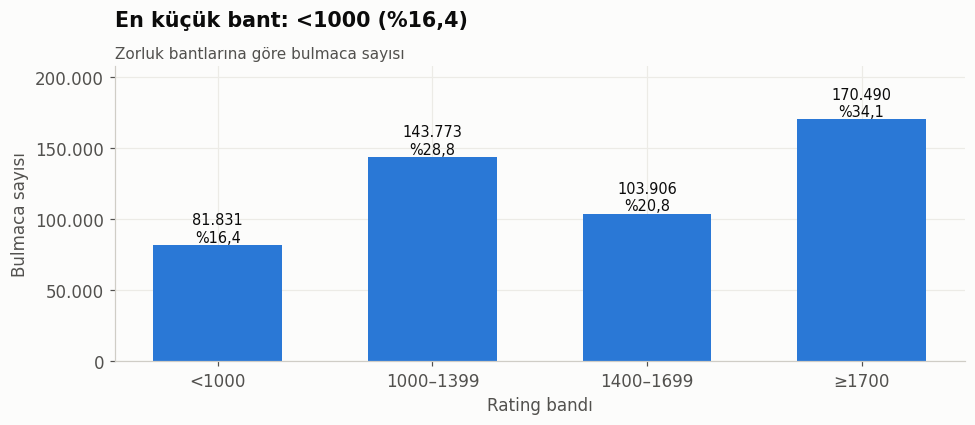

> 📌 **Bulgu:** En kalabalık bant en küçüğünün 2,1 katı. Doğrulama bölmesini bantlara göre katmanlı yapmak (ör. `StratifiedKFold`) ve hatayı her bant için ayrıca raporlamak gerekecek.

In [11]:
sayim = df["bant"].value_counts().reindex(BANT_AD)
fig, ax = plt.subplots(figsize=(9, 4))
cubuk = ax.bar(BANT_AD, sayim.values, color=MAVI, width=.6)
for c, v in zip(cubuk, sayim.values):
    ax.text(c.get_x() + c.get_width() / 2, v, f"{tr(v)}\n{yuzde(v / len(df))}", ha="center", va="bottom", fontsize=9.5, color=YAZI)
ax.set_ylim(0, sayim.max() * 1.22)
en_az = sayim.idxmin()
baslik(ax, f"En küçük bant: {en_az} ({yuzde(sayim.min() / len(df))})", "Zorluk bantlarına göre bulmaca sayısı")
ax.set_xlabel("Rating bandı"); ax.set_ylabel("Bulmaca sayısı")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: tr(v)))
plt.tight_layout(); plt.show()
bulgu(f"En kalabalık bant en küçüğünün {tr(sayim.max() / sayim.min(), 1)} katı. Doğrulama bölmesini bantlara göre katmanlı yapmak "
      "(ör. `StratifiedKFold`) ve hatayı her bant için ayrıca raporlamak gerekecek.")

## 3. Bulmacanın yapısı
Bu sütunlar hiç satranç kütüphanesi gerektirmeden çıkarılabiliyor; ilk modelin en ucuz öznitelikleri bunlar olacak.

### 3.1 Çözüm uzunluğu
Literatürde en güçlü basit öznitelik: çözüm uzadıkça oyuncunun ileriyi görmesi gerekiyor (GlickFormer 2024, Björkqvist 2025).

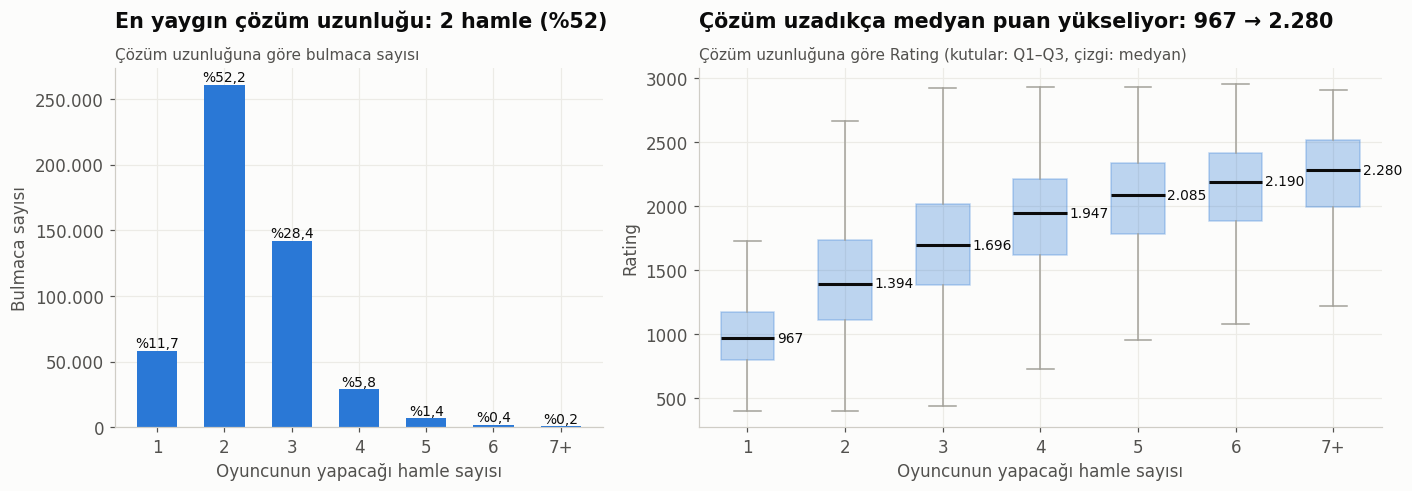

> 📌 **Bulgu:** Çözüm uzunluğu ile Rating arasındaki Spearman korelasyonu **0,49**. Tek bir sütunla bile kayda değer bir sinyal var.

In [12]:
uz = df["cozum_uzunlugu"].clip(upper=7)
etiket = {i: str(i) for i in range(1, 7)}; etiket[7] = "7+"
seviyeler = sorted(uz.unique())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
sayim = uz.value_counts().reindex(seviyeler)
ax1.bar([etiket[s] for s in seviyeler], sayim.values, color=MAVI, width=.6)
for i, v in enumerate(sayim.values):
    ax1.text(i, v, yuzde(v / len(df)), ha="center", va="bottom", fontsize=9, color=YAZI)
mod = sayim.idxmax()
baslik(ax1, f"En yaygın çözüm uzunluğu: {etiket[mod]} hamle ({yuzde(sayim.max() / len(df), 0)})", "Çözüm uzunluğuna göre bulmaca sayısı")
ax1.set_xlabel("Oyuncunun yapacağı hamle sayısı"); ax1.set_ylabel("Bulmaca sayısı")
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: tr(v)))

veri = [df.loc[uz == s, "Rating"].values for s in seviyeler]
kutu(ax2, veri, [etiket[s] for s in seviyeler])
ilk, son = np.median(veri[0]), np.median(veri[-1])
yon = "yükseliyor" if son > ilk else "düşüyor"
baslik(ax2, f"Çözüm uzadıkça medyan puan {yon}: {tr(ilk)} → {tr(son)}", "Çözüm uzunluğuna göre Rating (kutular: Q1–Q3, çizgi: medyan)")
ax2.set_xlabel("Oyuncunun yapacağı hamle sayısı"); ax2.set_ylabel("Rating")
plt.tight_layout(); plt.show()

r = df[["cozum_uzunlugu", "Rating"]].corr(method="spearman").iloc[0, 1]
bulgu(f"Çözüm uzunluğu ile Rating arasındaki Spearman korelasyonu **{tr(r, 2)}**. "
      + ("Tek bir sütunla bile kayda değer bir sinyal var." if abs(r) >= .2 else "Tek başına zayıf bir sinyal."))

### 3.2 Taktik temalar
`Themes` sütunu bulmacanın taktik motiflerini listeler. Hangi temalar insanları daha çok zorluyor?

⚠️ **Dikkat:** Yarışmaların test verisinde `Themes` sütunu yoktu ve etiketler kısmen oyuncu oylarıyla düzeltiliyor. Modelde kullanırsan raporda bunu belirtmen gerekir. Burada uzunluk ve evre bildiren meta-temaları (*short, long, opening, …*) ayrı tuttuk.

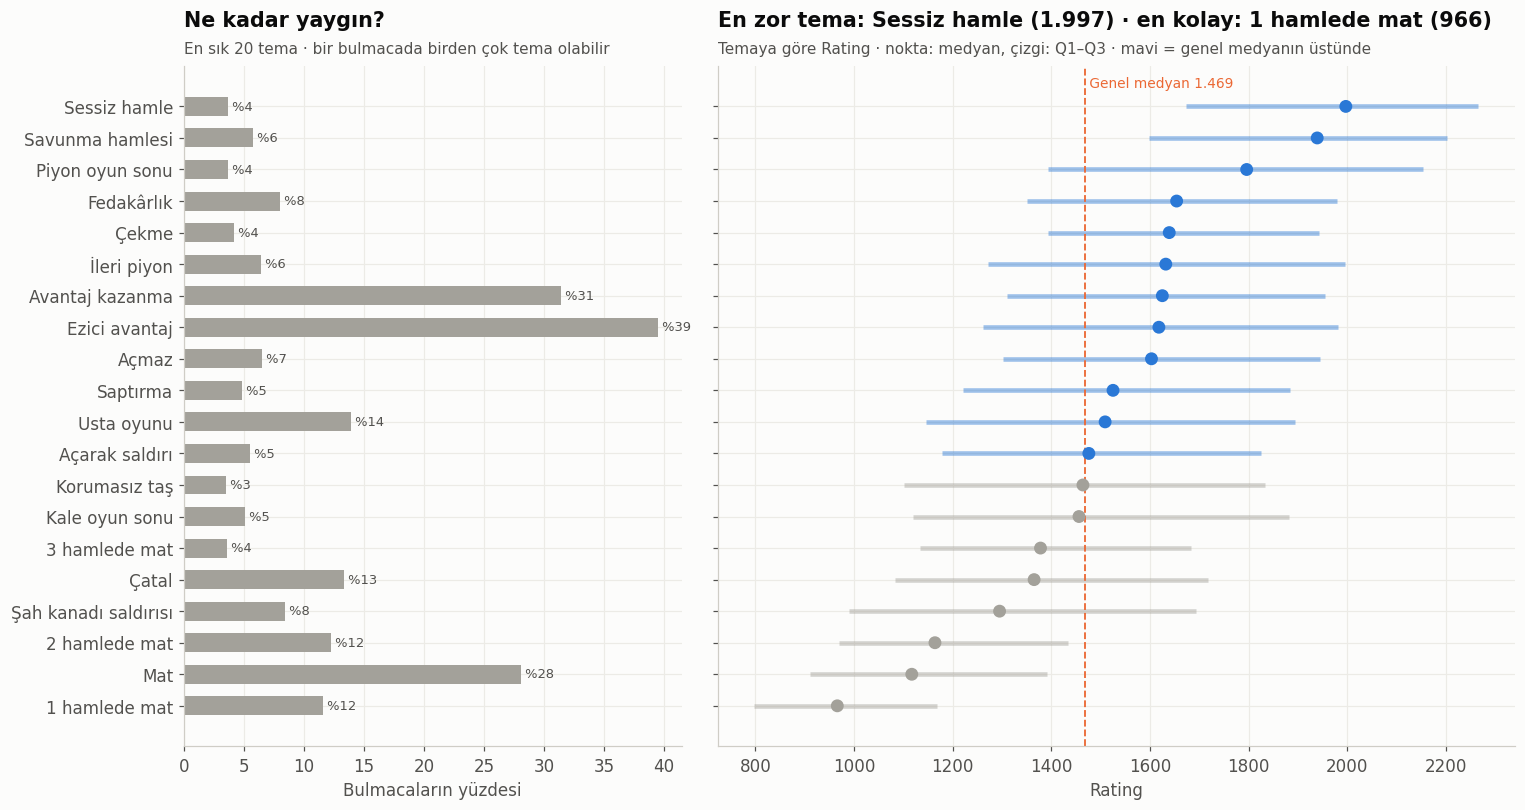

> 📌 **Bulgu:** En sık 20 temanın medyan puanı 966 ile 1.997 arasında değişiyor. Tema bilgisini kullanmak istersen, yarışmalarda olduğu gibi Lichess'in açık kaynak etiketleyicisiyle temaları çözüm hamlelerinden **yeniden üretmek** daha adil bir kurulum olur.

In [13]:
TEMA_TR = {
    "mate": "Mat", "mateIn1": "1 hamlede mat", "mateIn2": "2 hamlede mat", "mateIn3": "3 hamlede mat",
    "mateIn4": "4 hamlede mat", "mateIn5": "5+ hamlede mat", "fork": "Çatal", "pin": "Açmaz", "skewer": "Şiş",
    "sacrifice": "Fedakârlık", "discoveredAttack": "Açarak saldırı", "deflection": "Saptırma",
    "attraction": "Çekme", "hangingPiece": "Korumasız taş", "advantage": "Avantaj kazanma",
    "crushing": "Ezici avantaj", "equality": "Eşitliği kurtarma", "kingsideAttack": "Şah kanadı saldırısı",
    "queensideAttack": "Vezir kanadı saldırısı", "defensiveMove": "Savunma hamlesi", "quietMove": "Sessiz hamle",
    "rookEndgame": "Kale oyun sonu", "pawnEndgame": "Piyon oyun sonu", "queenEndgame": "Vezir oyun sonu",
    "bishopEndgame": "Fil oyun sonu", "knightEndgame": "At oyun sonu", "queenRookEndgame": "Vezir-kale oyun sonu",
    "backRankMate": "Arka sıra matı", "trappedPiece": "Kapana kısılmış taş", "exposedKing": "Açıktaki şah",
    "promotion": "Terfi", "advancedPawn": "İleri piyon", "capturingDefender": "Savunanı alma",
    "doubleCheck": "Çifte şah", "intermezzo": "Ara hamle", "interference": "Araya girme",
    "xRayAttack": "X-ışını saldırısı", "zugzwang": "Zugzwang", "clearance": "Yol açma",
    "smotheredMate": "Boğmaca mat", "attackingF2F7": "f2/f7 saldırısı", "master": "Usta oyunu",
    "masterVsMaster": "Usta – usta oyunu", "superGM": "Süper GM oyunu", "castling": "Rok",
    "enPassant": "Geçerken alma", "underPromotion": "Eksik terfi", "hookMate": "Kanca matı",
    "anastasiaMate": "Anastasia matı", "arabianMate": "Arap matı", "bodenMate": "Boden matı",
    "doubleBishopMate": "Çifte fil matı", "dovetailMate": "Kırlangıç kuyruğu matı",
}
META = {"short", "long", "veryLong", "oneMove", "opening", "middlegame", "endgame"}

tema = df[["Rating", "tema_listesi"]].explode("tema_listesi").rename(columns={"tema_listesi": "tema"})
tema = tema[tema["tema"].notna() & (tema["tema"] != "") & ~tema["tema"].isin(META)]
g = tema.groupby("tema")["Rating"]
tablo = pd.DataFrame({"adet": g.size(), "med": g.median(), "q1": g.quantile(.25), "q3": g.quantile(.75)})
tablo["pay"] = tablo["adet"] / len(df)
ust = tablo.nlargest(20, "adet").sort_values("med")
ust["ad"] = [TEMA_TR.get(t, t) for t in ust.index]
genel_med = df["Rating"].median()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7.5), sharey=True, gridspec_kw={"width_ratios": [1, 1.6]})
y = np.arange(len(ust))
ax1.barh(y, ust["pay"] * 100, color=GRI, height=.6)
for yi, p in zip(y, ust["pay"]):
    ax1.text(p * 100, yi, f" {yuzde(p, 0)}", va="center", fontsize=8.5, color=YAZI2)
ax1.set_yticks(y); ax1.set_yticklabels(ust["ad"])
ax1.set_xlabel("Bulmacaların yüzdesi")
baslik(ax1, "Ne kadar yaygın?", "En sık 20 tema · bir bulmacada birden çok tema olabilir")

renkler = [MAVI if m > genel_med else GRI for m in ust["med"]]
ax2.hlines(y, ust["q1"], ust["q3"], color=renkler, lw=3, alpha=.45)
ax2.scatter(ust["med"], y, color=renkler, s=55, zorder=3)
ax2.axvline(genel_med, color=TURUNCU, ls="--", lw=1.2)
ax2.text(genel_med, len(ust) - .4, f" Genel medyan {tr(genel_med)}", color=TURUNCU, fontsize=9)
en_zor, en_kolay = ust.iloc[-1], ust.iloc[0]
baslik(ax2, f"En zor tema: {en_zor['ad']} ({tr(en_zor['med'])}) · en kolay: {en_kolay['ad']} ({tr(en_kolay['med'])})",
       "Temaya göre Rating · nokta: medyan, çizgi: Q1–Q3 · mavi = genel medyanın üstünde")
ax2.set_xlabel("Rating")
plt.tight_layout(); plt.show()
bulgu(f"En sık 20 temanın medyan puanı {tr(ust['med'].min())} ile {tr(ust['med'].max())} arasında değişiyor. Tema bilgisini kullanmak istersen, yarışmalarda olduğu gibi Lichess'in açık kaynak etiketleyicisiyle temaları çözüm hamlelerinden **yeniden üretmek** daha adil bir kurulum olur.")

### 3.3 Oyun evresi ve çözen taraf
Açılış, orta oyun ve oyun sonu bulmacaları farklı becerileri ölçüyor olabilir. Çözen tarafın (beyaz/siyah) ise zorluğu etkilememesini bekliyoruz; bu bir **akıl sağlığı kontrolü**.

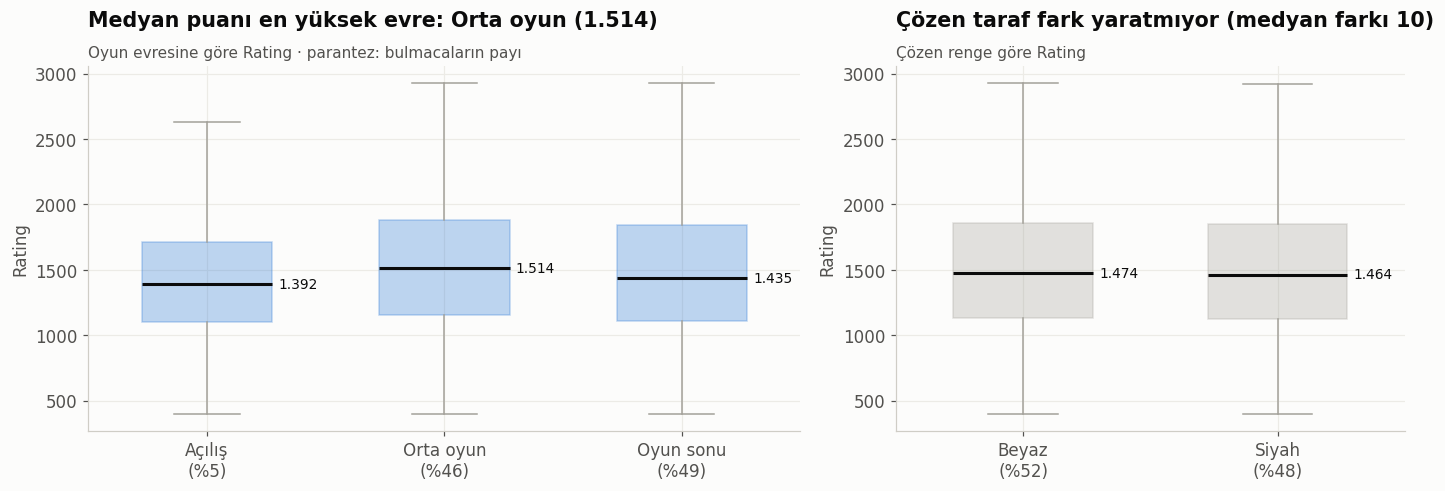

> 📌 **Bulgu:** Evreler arasındaki en büyük medyan farkı 122 puan, çözen renkler arasındaki fark 10 puan. Renk bilgisi neredeyse hiç sinyal taşımıyor; modelde gereksiz olabilir.

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
fazlar = [f for f in ["Açılış", "Orta oyun", "Oyun sonu", "Belirsiz"] if (df["faz"] == f).sum() > 0]
veri = [df.loc[df["faz"] == f, "Rating"].values for f in fazlar]
kutu(ax1, veri, [f"{f}\n({yuzde((df['faz'] == f).mean(), 0)})" for f in fazlar])
meds = {f: np.median(v) for f, v in zip(fazlar, veri)}
zor = max(meds, key=meds.get)
baslik(ax1, f"Medyan puanı en yüksek evre: {zor} ({tr(meds[zor])})", "Oyun evresine göre Rating · parantez: bulmacaların payı")
ax1.set_ylabel("Rating")

taraflar = ["Beyaz", "Siyah"]
veri2 = [df.loc[df["cozen_taraf"] == t, "Rating"].values for t in taraflar]
kutu(ax2, veri2, [f"{t}\n({yuzde((df['cozen_taraf'] == t).mean(), 0)})" for t in taraflar], renk=GRI)
fark = abs(np.median(veri2[0]) - np.median(veri2[1]))
baslik(ax2, (f"Çözen taraf fark yaratmıyor (medyan farkı {tr(fark)})" if fark < 25 else f"Çözen tarafa göre medyan farkı: {tr(fark)}"),
       "Çözen renge göre Rating")
ax2.set_ylabel("Rating")
plt.tight_layout(); plt.show()
aralik = max(meds.values()) - min(meds.values())
bulgu(f"Evreler arasındaki en büyük medyan farkı {tr(aralik)} puan, çözen renkler arasındaki fark {tr(fark)} puan. "
      + ("Renk bilgisi neredeyse hiç sinyal taşımıyor; modelde gereksiz olabilir." if fark < 25 else "Renk de bir miktar sinyal taşıyor."))

## 4. Tahtadan çıkarılan öznitelikler (`python-chess`)
Asıl modelin girdileri bunlar olacak. Hesaplama yavaş olduğu için **80.000 bulmacalık** rastgele bir alt örneklem kullanıyoruz.

⚠️ `FEN`, rakibin hamlesinden **önceki** pozisyondur. Oyuncunun gördüğü pozisyon, `Moves` içindeki **ilk hamle uygulandıktan sonraki** pozisyondur; tüm öznitelikleri o pozisyondan çıkarıyoruz.

| Öznitelik | Ne ölçüyor? | Literatürdeki karşılığı |
|---|---|---|
| `yasal_hamle` | Oyuncunun önündeki seçenek sayısı | Hristova vd. 2014: "makul varyant sayısı" zorluğun ana etkenlerinden |
| `zorlayici_hamle` | Şah çeken ya da taş alan hamle sayısı | Björkqvist 2025: *forcing moves* |
| `ilk_hamle_turu` | Doğru ilk hamle şah mı, alma mı, sessiz mi? | Sessiz hamleler insan gözünden kaçar |
| `hareket_eden_tas` | Doğru ilk hamleyi hangi taş yapıyor? | Björkqvist 2025: *piece type* |
| `tas_sayisi` | Tahtadaki toplam taş | Pozisyonun karmaşıklığı |
| `materyal_farki` | Çözenin materyal üstünlüğü (P=1, A/F=3, K=5, V=9) | Björkqvist 2025: *material diff* |
| `sah_altinda` | Oyuncu şah altında mı başlıyor? | Zorunlu cevap seçenekleri daraltır |

In [15]:
CHESS_OK = False
try:
    import chess
    CHESS_OK = True
except ImportError:
    print("python-chess yükleniyor…")
    os.system("pip install -q python-chess")
    try:
        import chess
        CHESS_OK = True
    except ImportError:
        print("⚠️ python-chess yüklenemedi (notebook ayarlarından Internet'i açman gerekebilir). Bölüm 4 atlanacak.")

if CHESS_OK:
    DEGER = {chess.PAWN: 1, chess.KNIGHT: 3, chess.BISHOP: 3, chess.ROOK: 5, chess.QUEEN: 9, chess.KING: 0}
    TAS_AD = {chess.PAWN: "Piyon", chess.KNIGHT: "At", chess.BISHOP: "Fil", chess.ROOK: "Kale", chess.QUEEN: "Vezir", chess.KING: "Şah"}

    def ozellik_cikar(fen, moves):
        tahta = chess.Board(fen)
        hamle_list = moves.split()
        tahta.push_uci(hamle_list[0])                  # rakibin hamlesi -> oyuncunun gördüğü pozisyon
        oyuncu = tahta.turn
        dogru = chess.Move.from_uci(hamle_list[1])     # çözümün ilk hamlesi
        yasal = list(tahta.legal_moves)
        zorlayici = sum(1 for m in yasal if tahta.is_capture(m) or tahta.gives_check(m))
        if tahta.gives_check(dogru):
            tur = "Şah çekme"
        elif tahta.is_capture(dogru):
            tur = "Taş alma"
        else:
            tur = "Sessiz"
        tas_map = tahta.piece_map()
        materyal = sum(DEGER[p.piece_type] * (1 if p.color == oyuncu else -1) for p in tas_map.values())
        return (len(yasal), zorlayici, tur, TAS_AD[tahta.piece_type_at(dogru.from_square)],
                len(tas_map), materyal, int(tahta.is_check()))

    N_ALT = min(80_000, len(df))
    alt = df.sample(n=N_ALT, random_state=7).reset_index(drop=True)
    t0 = time.time()
    sonuc = [ozellik_cikar(f, m) for f, m in zip(alt["FEN"], alt["Moves"])]
    kolonlar = ["yasal_hamle", "zorlayici_hamle", "ilk_hamle_turu", "hareket_eden_tas", "tas_sayisi", "materyal_farki", "sah_altinda"]
    alt[kolonlar] = pd.DataFrame(sonuc, columns=kolonlar)
    print(f"{tr(N_ALT)} bulmaca için öznitelikler {tr(time.time() - t0)} saniyede çıkarıldı.")
    display(alt[["Rating", "cozum_uzunlugu"] + kolonlar].head())

python-chess yükleniyor…
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 60.2 MB/s eta 0:00:00
80.000 bulmaca için öznitelikler 43 saniyede çıkarıldı.


Sütun,Rating,cozum_uzunlugu,yasal_hamle,zorlayici_hamle,ilk_hamle_turu,hareket_eden_tas,tas_sayisi,materyal_farki,sah_altinda
0,1397,2,39,4,Sessiz,Fil,24,0,0
1,1866,4,30,3,Şah çekme,Vezir,16,-2,0
2,959,1,37,5,Şah çekme,Vezir,14,0,0
3,1201,1,21,5,Şah çekme,Vezir,16,-2,0
4,1329,3,41,2,Şah çekme,Fil,22,0,0


### 4.1 Seçenek sayısı: yasal ve zorlayıcı hamleler
Grafikler, x eksenini aralıklara bölüp her aralıktaki **medyan puanı** (çizgi) ve **çeyrekler arası bandı** (gölge) gösteriyor. Saçılım grafiği yerine bu yöntemi kullanıyoruz; 80 bin nokta üst üste binince okunmuyor.

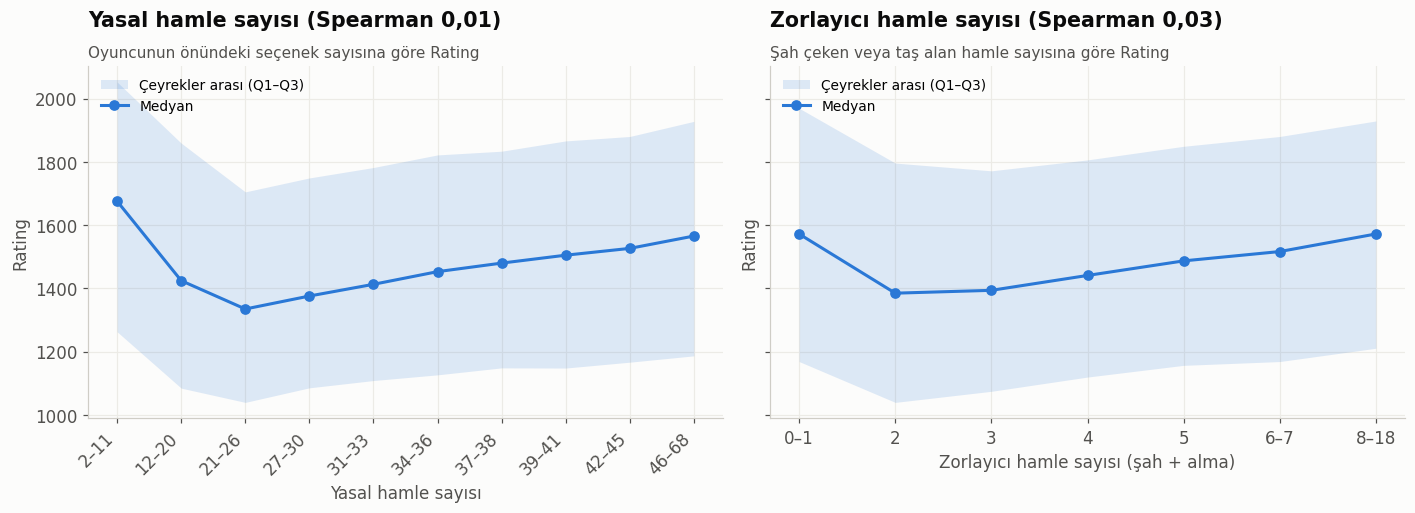

> 📌 **Bulgu:** Yasal hamle sayısının Rating ile korelasyonu 0,01, zorlayıcı hamle sayısınınki 0,03. Gölgeli bantların genişliği, tek bir özniteliğin zorluğu tek başına açıklayamayacağını gösteriyor.

In [16]:
if CHESS_OK:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
    o1 = binli_medyan(ax1, alt["yasal_hamle"], alt["Rating"], kantil_kenar(alt["yasal_hamle"]), xetiket="Yasal hamle sayısı")
    r1 = alt[["yasal_hamle", "Rating"]].corr(method="spearman").iloc[0, 1]
    baslik(ax1, f"Yasal hamle sayısı (Spearman {tr(r1, 2)})", "Oyuncunun önündeki seçenek sayısına göre Rating")

    o2 = binli_medyan(ax2, alt["zorlayici_hamle"], alt["Rating"], kantil_kenar(alt["zorlayici_hamle"], 8), xetiket="Zorlayıcı hamle sayısı (şah + alma)")
    r2 = alt[["zorlayici_hamle", "Rating"]].corr(method="spearman").iloc[0, 1]
    baslik(ax2, f"Zorlayıcı hamle sayısı (Spearman {tr(r2, 2)})", "Şah çeken veya taş alan hamle sayısına göre Rating")
    plt.tight_layout(); plt.show()
    bulgu(f"Yasal hamle sayısının Rating ile korelasyonu {tr(r1, 2)}, zorlayıcı hamle sayısınınki {tr(r2, 2)}. "
          "Gölgeli bantların genişliği, tek bir özniteliğin zorluğu tek başına açıklayamayacağını gösteriyor.")

### 4.2 Doğru ilk hamlenin türü ve hamleyi yapan taş
Şah çeken ve taş alan hamleler göze kolay batar; **sessiz** bir hamleyi bulmak genellikle daha zordur.

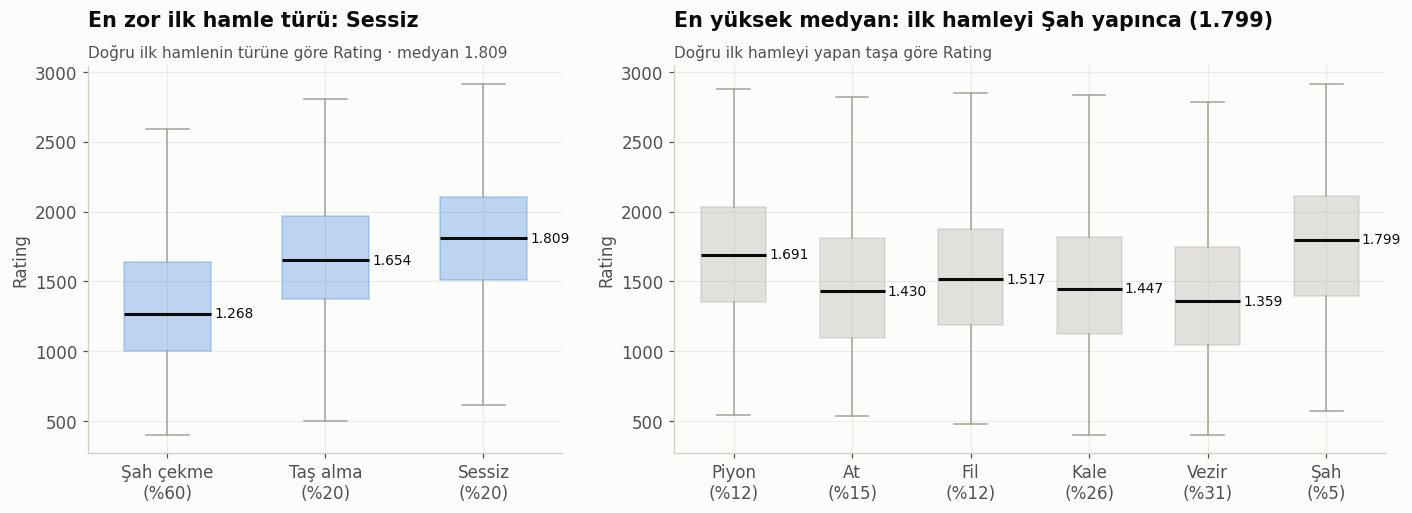

> 📌 **Bulgu:** Türler arasındaki medyan farkı 541, taşlar arasındaki 440 puan. İkisi de kategorik öznitelik olarak modele girmeye aday.

In [17]:
if CHESS_OK:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.5]})
    turler = ["Şah çekme", "Taş alma", "Sessiz"]
    veri = [alt.loc[alt["ilk_hamle_turu"] == t, "Rating"].values for t in turler]
    kutu(ax1, veri, [f"{t}\n({yuzde((alt['ilk_hamle_turu'] == t).mean(), 0)})" for t in turler])
    meds = dict(zip(turler, map(np.median, veri)))
    zor_tur = max(meds, key=meds.get)
    baslik(ax1, f"En zor ilk hamle türü: {zor_tur}", f"Doğru ilk hamlenin türüne göre Rating · medyan {tr(meds[zor_tur])}")
    ax1.set_ylabel("Rating")

    taslar = [t for t in ["Piyon", "At", "Fil", "Kale", "Vezir", "Şah"] if (alt["hareket_eden_tas"] == t).sum() >= 50]
    veri2 = [alt.loc[alt["hareket_eden_tas"] == t, "Rating"].values for t in taslar]
    kutu(ax2, veri2, [f"{t}\n({yuzde((alt['hareket_eden_tas'] == t).mean(), 0)})" for t in taslar], renk=GRI)
    meds2 = dict(zip(taslar, map(np.median, veri2)))
    zor = max(meds2, key=meds2.get)
    baslik(ax2, f"En yüksek medyan: ilk hamleyi {zor} yapınca ({tr(meds2[zor])})", "Doğru ilk hamleyi yapan taşa göre Rating")
    ax2.set_ylabel("Rating")
    plt.tight_layout(); plt.show()
    bulgu(f"Türler arasındaki medyan farkı {tr(max(meds.values()) - min(meds.values()))}, taşlar arasındaki {tr(max(meds2.values()) - min(meds2.values()))} puan. "
          "İkisi de kategorik öznitelik olarak modele girmeye aday.")

### 4.3 Tahtadaki taş sayısı ve materyal dengesi

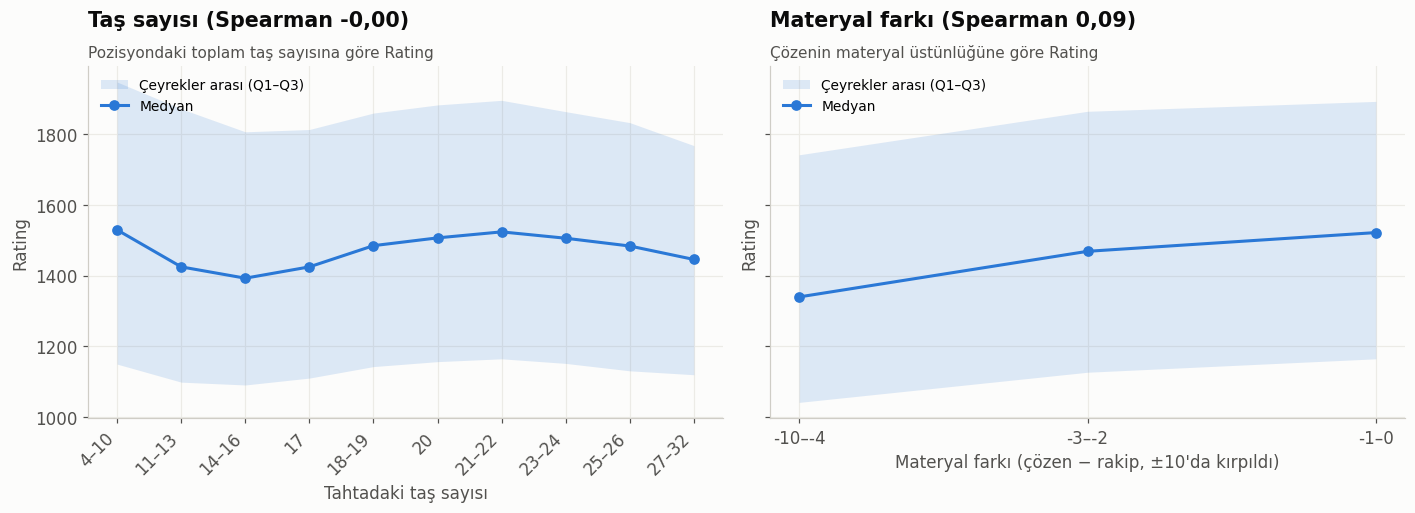

> 📌 **Bulgu:** Taş sayısının korelasyonu -0,00, materyal farkınınki 0,09.

In [18]:
if CHESS_OK:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
    binli_medyan(ax1, alt["tas_sayisi"], alt["Rating"], kantil_kenar(alt["tas_sayisi"]), xetiket="Tahtadaki taş sayısı")
    r1 = alt[["tas_sayisi", "Rating"]].corr(method="spearman").iloc[0, 1]
    baslik(ax1, f"Taş sayısı (Spearman {tr(r1, 2)})", "Pozisyondaki toplam taş sayısına göre Rating")

    mf = alt["materyal_farki"].clip(-10, 10)
    binli_medyan(ax2, mf, alt["Rating"], [-11, -4, -2, 0, 1, 2, 4, 10], xetiket="Materyal farkı (çözen − rakip, ±10'da kırpıldı)")
    r2 = alt[["materyal_farki", "Rating"]].corr(method="spearman").iloc[0, 1]
    baslik(ax2, f"Materyal farkı (Spearman {tr(r2, 2)})", "Çözenin materyal üstünlüğüne göre Rating")
    plt.tight_layout(); plt.show()
    bulgu(f"Taş sayısının korelasyonu {tr(r1, 2)}, materyal farkınınki {tr(r2, 2)}.")

### 4.4 Tüm özniteliklerin Rating ile ilişkisi
Soldaki grafik her özniteliğin Rating ile **Spearman** korelasyonunu sıralıyor (doğrusal olmayan ama tek yönlü ilişkileri de yakalar). Sağdaki ısı haritası öznitelikler arasındaki korelasyonu gösteriyor; birbirine çok benzeyen öznitelikler modele aynı bilgiyi iki kez verir.

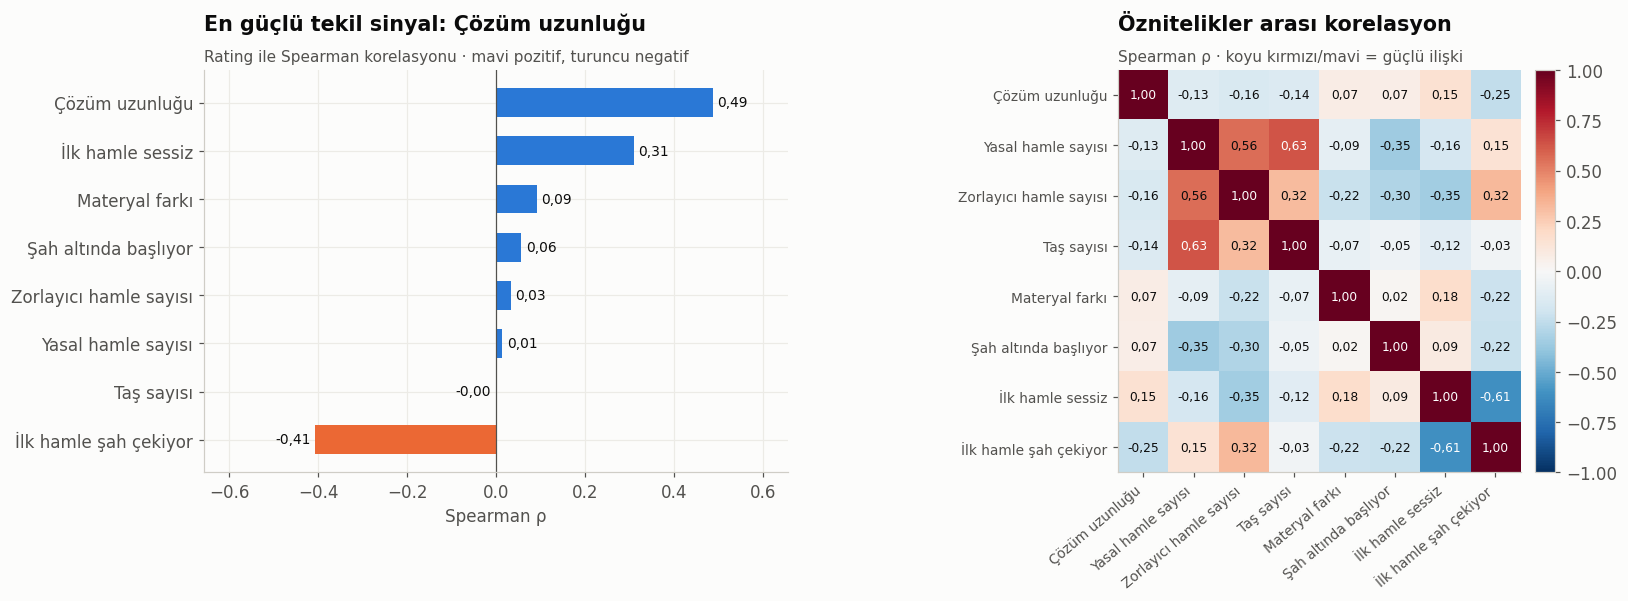

> 📌 **Bulgu:** En güçlü tekil korelasyon |ρ| = 0,49; tek başına hiçbir öznitelik zorluğu tam açıklamıyor, bu yüzden ağaç tabanlı bir model (LightGBM) öznitelikleri birlikte kullanmalı. Birbiriyle |ρ| > 0,6 olan çiftler: Yasal hamle sayısı – Taş sayısı (0,63); İlk hamle sessiz – İlk hamle şah çekiyor (-0,61).

In [19]:
if CHESS_OK:
    alt["ilk_hamle_sessiz"] = (alt["ilk_hamle_turu"] == "Sessiz").astype(int)
    alt["ilk_hamle_sah"] = (alt["ilk_hamle_turu"] == "Şah çekme").astype(int)
    ADLAR = {
        "cozum_uzunlugu": "Çözüm uzunluğu", "yasal_hamle": "Yasal hamle sayısı",
        "zorlayici_hamle": "Zorlayıcı hamle sayısı", "tas_sayisi": "Taş sayısı",
        "materyal_farki": "Materyal farkı", "sah_altinda": "Şah altında başlıyor",
        "ilk_hamle_sessiz": "İlk hamle sessiz", "ilk_hamle_sah": "İlk hamle şah çekiyor",
    }
    kor = alt[list(ADLAR) + ["Rating"]].corr(method="spearman")
    hedef = kor["Rating"].drop("Rating").rename(ADLAR).sort_values()

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1, 1.25]})
    renk = [MAVI if v > 0 else TURUNCU for v in hedef.values]
    ax1.barh(hedef.index, hedef.values, color=renk, height=.6)
    for i, v in enumerate(hedef.values):
        ax1.text(v + (.01 if v >= 0 else -.01), i, tr(v, 2), va="center", ha="left" if v >= 0 else "right", fontsize=9, color=YAZI)
    ax1.axvline(0, color=YAZI2, lw=.8)
    lim = max(abs(hedef).max() * 1.35, .1)
    ax1.set_xlim(-lim, lim)
    baslik(ax1, f"En güçlü tekil sinyal: {hedef.abs().idxmax()}", "Rating ile Spearman korelasyonu · mavi pozitif, turuncu negatif")
    ax1.set_xlabel("Spearman ρ")

    m = kor.drop(index="Rating", columns="Rating").rename(index=ADLAR, columns=ADLAR)
    im = ax2.imshow(m.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax2.set_xticks(range(len(m))); ax2.set_xticklabels(m.columns, rotation=40, ha="right", fontsize=9)
    ax2.set_yticks(range(len(m))); ax2.set_yticklabels(m.index, fontsize=9)
    for i in range(len(m)):
        for j in range(len(m)):
            v = m.values[i, j]
            ax2.text(j, i, tr(v, 2), ha="center", va="center", fontsize=8, color="white" if abs(v) > .6 else YAZI)
    ax2.grid(False)
    fig.colorbar(im, ax=ax2, fraction=.046, pad=.02)
    baslik(ax2, "Öznitelikler arası korelasyon", "Spearman ρ · koyu kırmızı/mavi = güçlü ilişki")
    plt.tight_layout(); plt.show()

    yuksek_cift = [(a, b, m.loc[a, b]) for i, a in enumerate(m.index) for b in m.columns[i + 1:] if abs(m.loc[a, b]) > .6]
    metin = "; ".join(f"{a} – {b} ({tr(v, 2)})" for a, b, v in yuksek_cift) or "yok"
    bulgu(f"En güçlü tekil korelasyon |ρ| = {tr(hedef.abs().max(), 2)}; tek başına hiçbir öznitelik zorluğu tam açıklamıyor, bu yüzden ağaç tabanlı bir model (LightGBM) öznitelikleri birlikte kullanmalı. "
          f"Birbiriyle |ρ| > 0,6 olan çiftler: {metin}.")

## 5. Sızıntı (leakage) kontrolü
`NbPlays` (oynanma sayısı) ve `Popularity` (oy skoru) bulmaca **çözüldükten sonra** oluşur. Yeni bir bulmaca için bu bilgiler henüz yoktur. Rating ile ilişkileri güçlü görünse bile **modele girmeyecekler**; bu grafik o kararı belgelemek için.

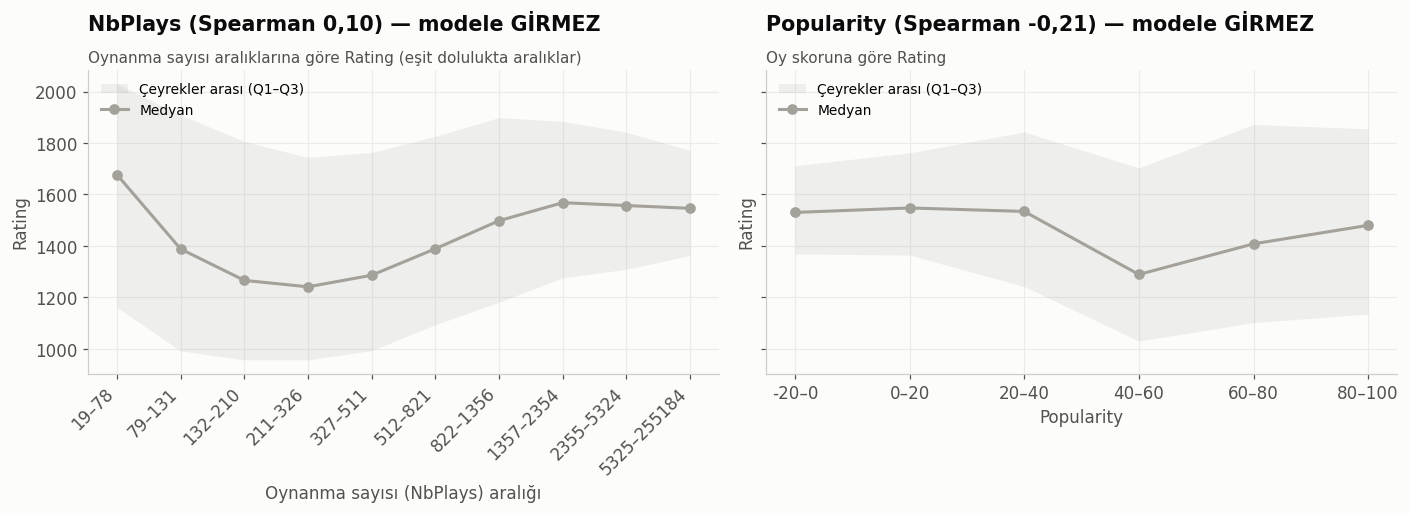

> 📌 **Bulgu:** Bu iki sütun ve `RatingDeviation` sadece analiz ve filtreleme için kullanılacak. Modele sadece tahtadan ve çözüm hamlelerinden türetilen bilgiler girecek.

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
binli_medyan(ax1, df["NbPlays"], df["Rating"], kantil_kenar(df["NbPlays"]), renk=GRI, xetiket="Oynanma sayısı (NbPlays) aralığı")
r1 = df[["NbPlays", "Rating"]].corr(method="spearman").iloc[0, 1]
baslik(ax1, f"NbPlays (Spearman {tr(r1, 2)}) — modele GİRMEZ", "Oynanma sayısı aralıklarına göre Rating (eşit dolulukta aralıklar)")

binli_medyan(ax2, df["Popularity"], df["Rating"], np.arange(-100, 101, 20), renk=GRI, xetiket="Popularity", tamsayi=False)
r2 = df[["Popularity", "Rating"]].corr(method="spearman").iloc[0, 1]
baslik(ax2, f"Popularity (Spearman {tr(r2, 2)}) — modele GİRMEZ", "Oy skoruna göre Rating")
plt.tight_layout(); plt.show()
bulgu("Bu iki sütun ve `RatingDeviation` sadece analiz ve filtreleme için kullanılacak. Modele sadece tahtadan ve çözüm hamlelerinden türetilen bilgiler girecek.")

## 6. Özet
Aşağıdaki tablo bu notebook'ta hesaplanan temel sayıları tek yerde topluyor.

In [21]:
satirlar = [
    ("Örneklemdeki bulmaca", tr(len(df))),
    ("Rating ortalaması / medyanı", f"{tr(df['Rating'].mean())} / {tr(df['Rating'].median())}"),
    ("Rating standart sapması", tr(df["Rating"].std())),
    ("Bulmacaların %90'ının aralığı", f"{tr(df['Rating'].quantile(.05))} – {tr(df['Rating'].quantile(.95))}"),
    ("Medyan çözüm uzunluğu (hamle)", tr(df["cozum_uzunlugu"].median())),
    ("Çözüm uzunluğu – Rating (Spearman)", tr(df[["cozum_uzunlugu", "Rating"]].corr(method="spearman").iloc[0, 1], 2)),
]
if TUM_OK:
    satirlar.insert(1, ("Tam veride RD > 90 olan bulmaca payı", yuzde((tum["RatingDeviation"] > 90).mean())))
if CHESS_OK:
    satirlar += [(f"{ADLAR[k]} – Rating (Spearman)", tr(kor.loc[k, "Rating"], 2)) for k in ["yasal_hamle", "zorlayici_hamle", "tas_sayisi", "materyal_farki"]]
    satirlar.append(("Mutlak değerce en güçlü tekil öznitelik", hedef.abs().idxmax()))
display(pd.DataFrame(satirlar, columns=["Ölçüm", "Değer"]).set_index("Ölçüm"))

,Değer
Ölçüm,
Örneklemdeki bulmaca,500.000
Tam veride RD > 90 olan bulmaca payı,"%22,7"
Rating ortalaması / medyanı,1.501 / 1.469
Rating standart sapması,476
Bulmacaların %90'ının aralığı,790 – 2.316
Medyan çözüm uzunluğu (hamle),2
Çözüm uzunluğu – Rating (Spearman),"0,49"
Yasal hamle sayısı – Rating (Spearman),"0,01"
Zorlayıcı hamle sayısı – Rating (Spearman),"0,03"


### Modelleme için kararlar
1. **Veri:** `RatingDeviation ≤ 90` filtresi uygulanmış 500 bin bulmaca. 1500 yığılması büyük ölçüde temizlendi.
2. **Girdiler:** Sadece `FEN` ve `Moves`'tan türetilen öznitelikler (bölüm 3.1 ve 4). `Themes` kullanılacaksa çözüm hamlelerinden yeniden üretilecek ve raporda belirtilecek.
3. **Dışarıda kalanlar:** `RatingDeviation`, `NbPlays`, `Popularity` (sızıntı); `GameUrl`, `DailyDate` (bilgi taşımıyor).
4. **Model:** Tek başına güçlü bir öznitelik olmadığı için öznitelik etkileşimlerini yakalayan **LightGBM** regresyonu.
5. **Değerlendirme:** MSE, RMSE ve MAE; hatayı ayrıca **zorluk bantlarına göre** raporla (uçlardaki hata literatürde açık bir problem). Doğrulama bölmesi bantlara göre katmanlı (stratified) yapılsın.

### Sonraki adım
Bölüm 4'teki öznitelik fonksiyonunu tüm 500 bin bulmacaya uygula, bir **taban çizgisi** (herkese ortalama puanı veren model) ve **LightGBM** modeli kur, sonra SHAP ile öznitelik önemini incele.